In [1]:
import os
import random
import torch
import torch.nn as nn
import torch.nn.parallel
import torch.backends.cudnn as cudnn
import torch.optim as optim
import torch.utils.data
import torchvision.datasets as dset
import torchvision.transforms as transforms
import torchvision.utils as vutils
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

from parameters import *
from dataloader import *
from model import * 

In [2]:
# Set random seed for reproducibility
manualSeed = 999
#manualSeed = random.randint(1, 10000) # use if you want new results
print("Random Seed: ", manualSeed)
random.seed(manualSeed)
torch.manual_seed(manualSeed)

# Create the dataloader
dataloader = get_dataset()

# Decide which device we want to run on
device = torch.device("cuda:0" if (torch.cuda.is_available() and ngpu > 0) else "cpu")

Random Seed:  999


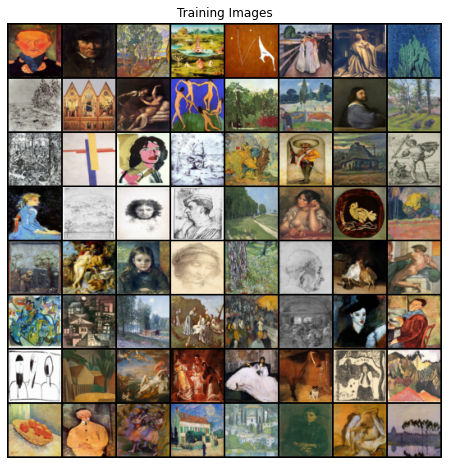

In [3]:
# Plot some training images
real_batch = next(iter(dataloader))
plt.figure(figsize=(8,8))
plt.axis("off")
plt.title("Training Images")
plt.imshow(np.transpose(vutils.make_grid(real_batch[0].to(device)[:64], padding=2, normalize=True).cpu(),(1,2,0)))

In [4]:
# Create the generator
netG = Generator(ngpu).to(device)

# # Handle multi-gpu if desired
# if (device.type == 'cuda') and (ngpu > 1):
#     netG = nn.DataParallel(netG, list(range(ngpu)))

# Apply the weights_init function to randomly initialize all weights
#  to mean=0, stdev=0.2.
netG.apply(weights_init)

# Print the model
print(netG)

Generator(
  (main): Sequential(
    (0): ConvTranspose2d(150, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
  )
)


In [5]:
# Create the Discriminator
netD = Discriminator(ngpu).to(device)

# # Handle multi-gpu if desired
# if (device.type == 'cuda') and (ngpu > 1):
#     netD = nn.DataParallel(netD, list(range(ngpu)))

# Apply the weights_init function to randomly initialize all weights
#  to mean=0, stdev=0.2.
netD.apply(weights_init)

# Print the model
print(netD)

Discriminator(
  (main): Sequential(
    (0): Conv2d(3, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (6): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (9): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.2, inplace=True)
    (11): Conv2d(512, 1, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (12): Sigmoid()
  )
)


In [6]:
# Initialize BCELoss function
criterion = nn.BCELoss()

# Create batch of latent vectors that we will use to visualize
#  the progression of the generator
fixed_noise = torch.randn(64, nz, 1, 1, device=device)

# Establish convention for real and fake labels during training
real_label = 1.
fake_label = 0.

# Setup Adam optimizers for both G and D
optimizerD = optim.Adam(netD.parameters(), lr=lr, betas=(beta1, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=lr, betas=(beta1, 0.999))

In [7]:
# Training Loop

# Lists to keep track of progress
img_list = []
G_losses = []
D_losses = []
iters = 0

print("Starting Training Loop...")
# For each epoch
for epoch in range(num_epochs):
    # For each batch in the dataloader
    for i, data in enumerate(dataloader, 0):

        ############################
        # (1) Update D network: maximize log(D(x)) + log(1 - D(G(z)))
        ###########################
        ## Train with all-real batch
        netD.zero_grad()
        # Format batch
        real_cpu = data[0].to(device)
        b_size = real_cpu.size(0)
        label = torch.full((b_size,), real_label, dtype=torch.float, device=device)
        # Forward pass real batch through D
        output = netD(real_cpu).view(-1)
        # Calculate loss on all-real batch
        errD_real = criterion(output, label)
        # Calculate gradients for D in backward pass
        errD_real.backward()
        D_x = output.mean().item()

        ## Train with all-fake batch
        # Generate batch of latent vectors
        noise = torch.randn(b_size, nz, 1, 1, device=device)
        # Generate fake image batch with G
        fake = netG(noise)
        label.fill_(fake_label)
        # Classify all fake batch with D
        output = netD(fake.detach()).view(-1)
        # Calculate D's loss on the all-fake batch
        errD_fake = criterion(output, label)
        # Calculate the gradients for this batch
        errD_fake.backward()
        D_G_z1 = output.mean().item()
        # Add the gradients from the all-real and all-fake batches
        errD = errD_real + errD_fake
        # Update D
        optimizerD.step()

        ############################
        # (2) Update G network: maximize log(D(G(z)))
        ###########################
        netG.zero_grad()
        label.fill_(real_label)  # fake labels are real for generator cost
        # Since we just updated D, perform another forward pass of all-fake batch through D
        output = netD(fake).view(-1)
        # Calculate G's loss based on this output
        errG = criterion(output, label)
        # Calculate gradients for G
        errG.backward()
        D_G_z2 = output.mean().item()
        # Update G
        optimizerG.step()

        # Output training stats
        if i % 50 == 0:
            print('[%d/%d][%d/%d]\tLoss_D: %.4f\tLoss_G: %.4f\tD(x): %.4f\tD(G(z)): %.4f / %.4f'
                  % (epoch, num_epochs, i, len(dataloader),
                     errD.item(), errG.item(), D_x, D_G_z1, D_G_z2))

        # Save Losses for plotting later
        G_losses.append(errG.item())
        D_losses.append(errD.item())

        # Check how the generator is doing by saving G's output on fixed_noise
        if (iters % 500 == 0) or ((epoch == num_epochs-1) and (i == len(dataloader)-1)):
            with torch.no_grad():
                fake = netG(fixed_noise).detach().cpu()
            img_list.append(vutils.make_grid(fake, padding=2, normalize=True))

        iters += 1

Starting Training Loop...
[0/150][0/68]	Loss_D: 1.8589	Loss_G: 26.7755	D(x): 0.5272	D(G(z)): 0.6057 / 0.0000
[0/150][50/68]	Loss_D: 1.3124	Loss_G: 1.8329	D(x): 0.6291	D(G(z)): 0.4630 / 0.1910
[1/150][0/68]	Loss_D: 1.5058	Loss_G: 5.9604	D(x): 0.8542	D(G(z)): 0.6553 / 0.0080
[1/150][50/68]	Loss_D: 1.0538	Loss_G: 1.1672	D(x): 0.5627	D(G(z)): 0.3396 / 0.3357
[2/150][0/68]	Loss_D: 0.7013	Loss_G: 2.3658	D(x): 0.7118	D(G(z)): 0.2757 / 0.1443
[2/150][50/68]	Loss_D: 1.0840	Loss_G: 1.5458	D(x): 0.7131	D(G(z)): 0.4278 / 0.3112
[3/150][0/68]	Loss_D: 2.3603	Loss_G: 4.9879	D(x): 0.9823	D(G(z)): 0.7434 / 0.0428
[3/150][50/68]	Loss_D: 1.4185	Loss_G: 1.2645	D(x): 0.4311	D(G(z)): 0.1180 / 0.3406
[4/150][0/68]	Loss_D: 1.3661	Loss_G: 2.8087	D(x): 0.5187	D(G(z)): 0.3657 / 0.1418
[4/150][50/68]	Loss_D: 0.6356	Loss_G: 2.0345	D(x): 0.7288	D(G(z)): 0.2458 / 0.1498
[5/150][0/68]	Loss_D: 0.4244	Loss_G: 2.7313	D(x): 0.7771	D(G(z)): 0.1272 / 0.0877
[5/150][50/68]	Loss_D: 0.8190	Loss_G: 2.8206	D(x): 0.6957	D(G(z)):

[49/150][50/68]	Loss_D: 1.0756	Loss_G: 2.3354	D(x): 0.5449	D(G(z)): 0.2151 / 0.1426
[50/150][0/68]	Loss_D: 1.3496	Loss_G: 1.1939	D(x): 0.3696	D(G(z)): 0.0942 / 0.3824
[50/150][50/68]	Loss_D: 0.6148	Loss_G: 3.7184	D(x): 0.9246	D(G(z)): 0.3572 / 0.0399
[51/150][0/68]	Loss_D: 0.9170	Loss_G: 3.5442	D(x): 0.8087	D(G(z)): 0.4271 / 0.0444
[51/150][50/68]	Loss_D: 0.6391	Loss_G: 2.7312	D(x): 0.6707	D(G(z)): 0.1350 / 0.1055
[52/150][0/68]	Loss_D: 0.9593	Loss_G: 3.9592	D(x): 0.8567	D(G(z)): 0.4537 / 0.0367
[52/150][50/68]	Loss_D: 0.6484	Loss_G: 2.8300	D(x): 0.6741	D(G(z)): 0.1228 / 0.1165
[53/150][0/68]	Loss_D: 1.1050	Loss_G: 4.5251	D(x): 0.8138	D(G(z)): 0.5159 / 0.0200
[53/150][50/68]	Loss_D: 1.1865	Loss_G: 1.6395	D(x): 0.4021	D(G(z)): 0.0699 / 0.2751
[54/150][0/68]	Loss_D: 1.0813	Loss_G: 1.8018	D(x): 0.4393	D(G(z)): 0.0580 / 0.2547
[54/150][50/68]	Loss_D: 0.8912	Loss_G: 2.2407	D(x): 0.6342	D(G(z)): 0.2364 / 0.1605
[55/150][0/68]	Loss_D: 0.9394	Loss_G: 3.6470	D(x): 0.7976	D(G(z)): 0.4369 / 0.044

[99/150][0/68]	Loss_D: 1.1547	Loss_G: 1.8062	D(x): 0.5589	D(G(z)): 0.2730 / 0.2760
[99/150][50/68]	Loss_D: 0.7351	Loss_G: 2.3967	D(x): 0.6542	D(G(z)): 0.1229 / 0.1795
[100/150][0/68]	Loss_D: 0.3346	Loss_G: 4.4182	D(x): 0.9127	D(G(z)): 0.1824 / 0.0247
[100/150][50/68]	Loss_D: 0.3659	Loss_G: 3.5545	D(x): 0.8873	D(G(z)): 0.1573 / 0.0555
[101/150][0/68]	Loss_D: 0.2887	Loss_G: 3.1555	D(x): 0.8066	D(G(z)): 0.0467 / 0.0847
[101/150][50/68]	Loss_D: 0.1938	Loss_G: 4.5444	D(x): 0.9741	D(G(z)): 0.1254 / 0.0263
[102/150][0/68]	Loss_D: 0.2659	Loss_G: 4.3869	D(x): 0.8706	D(G(z)): 0.0730 / 0.0281
[102/150][50/68]	Loss_D: 0.2754	Loss_G: 4.5902	D(x): 0.8895	D(G(z)): 0.1133 / 0.0251
[103/150][0/68]	Loss_D: 0.3275	Loss_G: 3.8780	D(x): 0.8979	D(G(z)): 0.1520 / 0.0434
[103/150][50/68]	Loss_D: 0.3837	Loss_G: 4.7930	D(x): 0.9025	D(G(z)): 0.1701 / 0.0173
[104/150][0/68]	Loss_D: 0.2881	Loss_G: 3.9090	D(x): 0.8186	D(G(z)): 0.0369 / 0.0570
[104/150][50/68]	Loss_D: 0.7002	Loss_G: 4.0234	D(x): 0.8259	D(G(z)): 0.25

[147/150][50/68]	Loss_D: 0.0734	Loss_G: 5.7953	D(x): 0.9844	D(G(z)): 0.0475 / 0.0113
[148/150][0/68]	Loss_D: 0.0488	Loss_G: 6.3910	D(x): 0.9852	D(G(z)): 0.0292 / 0.0068
[148/150][50/68]	Loss_D: 0.0290	Loss_G: 7.9252	D(x): 0.9801	D(G(z)): 0.0075 / 0.0022
[149/150][0/68]	Loss_D: 0.1242	Loss_G: 6.5546	D(x): 0.9162	D(G(z)): 0.0054 / 0.0125
[149/150][50/68]	Loss_D: 0.0377	Loss_G: 6.9047	D(x): 0.9828	D(G(z)): 0.0182 / 0.0055


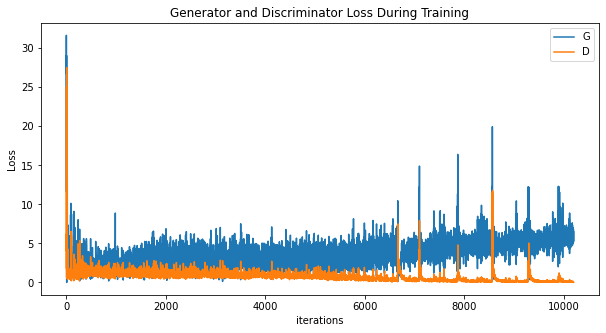

In [8]:
# Plot Losses
plt.figure(figsize=(10,5))
plt.title("Generator and Discriminator Loss During Training")
plt.plot(G_losses,label="G")
plt.plot(D_losses,label="D")
plt.xlabel("iterations")
plt.ylabel("Loss")
plt.legend()
plt.show()

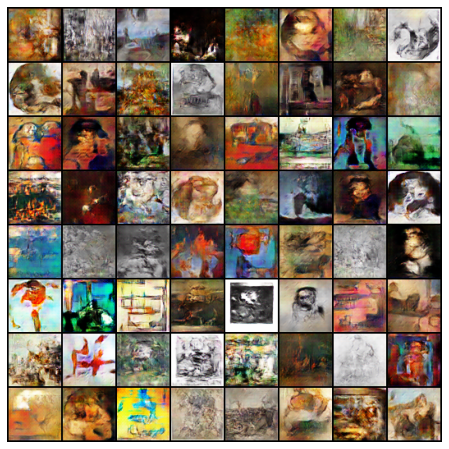

In [9]:
# Visualize G's Progress
fig = plt.figure(figsize=(8,8))
plt.axis("off")
ims = [[plt.imshow(np.transpose(i,(1,2,0)), animated=True)] for i in img_list]
ani = animation.ArtistAnimation(fig, ims, interval=1000, repeat_delay=1000, blit=True)

HTML(ani.to_jshtml())

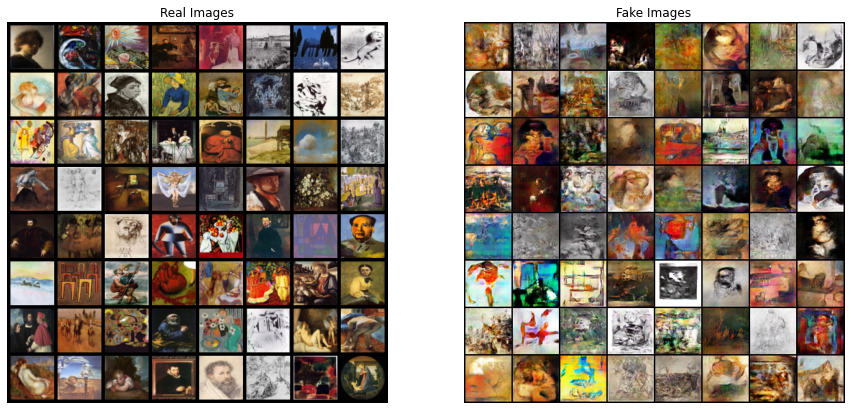

In [10]:
# Real vs Fake
# Grab a batch of real images from the dataloader
real_batch = next(iter(dataloader))

# Plot the real images
plt.figure(figsize=(15,15))
plt.subplot(1,2,1)
plt.axis("off")
plt.title("Real Images")
plt.imshow(np.transpose(vutils.make_grid(real_batch[0].to(device)[:64], padding=5, normalize=True).cpu(),(1,2,0)))

# Plot the fake images from the last epoch
plt.subplot(1,2,2)
plt.axis("off")
plt.title("Fake Images")
plt.imshow(np.transpose(img_list[-1],(1,2,0)))
plt.show()